# Transformers, Attention, and Embeddings

> Learn attention as weighted information retrieval between token representations.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Compute scaled dot-product attention using NumPy.
- Understand queries, keys, values, masking, and positional information.
- Distinguish a token embedding from a full contextual representation.

A transformer layer uses attention to let each token combine information from other tokens. The standard scaled dot-product equation is `softmax(Q Kᵀ / sqrt(d_k)) V`. This notebook demonstrates the operation with tiny made-up vectors; it does not load a large model.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
rng = np.random.default_rng(9)
sequence_length, d_model, d_k = 4, 6, 3
X = rng.normal(size=(sequence_length, d_model))
Wq, Wk, Wv = (rng.normal(size=(d_model, d_k)) for _ in range(3))
Q, K, V = X @ Wq, X @ Wk, X @ Wv
scores = Q @ K.T / np.sqrt(d_k)
weights = np.exp(scores - scores.max(axis=1, keepdims=True))
weights = weights / weights.sum(axis=1, keepdims=True)
context = weights @ V
print("Q, K, V shapes:", Q.shape, K.shape, V.shape)
print("Attention output shape:", context.shape)
print("Each attention row sums to:", weights.sum(axis=1).round(4))

Q, K, V shapes: (4, 3) (4, 3) (4, 3)
Attention output shape: (4, 3)
Each attention row sums to: [1. 1. 1. 1.]


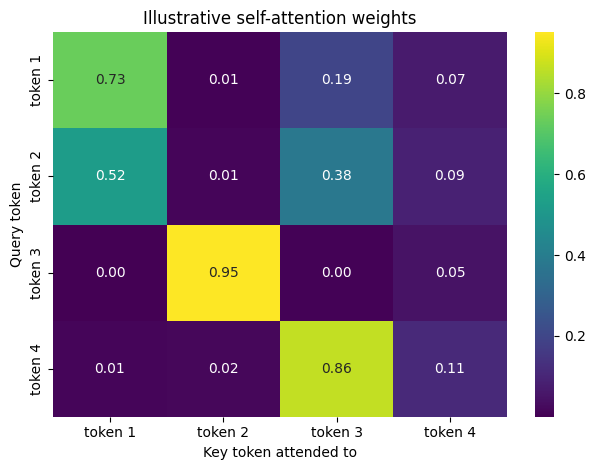

In [2]:
sns.heatmap(weights, annot=True, fmt=".2f", cmap="viridis", xticklabels=["token 1","token 2","token 3","token 4"], yticklabels=["token 1","token 2","token 3","token 4"])
plt.title("Illustrative self-attention weights")
plt.xlabel("Key token attended to")
plt.ylabel("Query token")
plt.tight_layout()

## Why the details matter
- **Queries:** what a token is looking for in other token representations.
- **Keys:** what each token offers for matching.
- **Values:** the information combined according to attention weights.
- **Positional information:** attention alone does not inherently know the original order; transformer designs add position information or related mechanisms.
- **Masking:** can block future positions in autoregressive language modeling or hide padding tokens.
- **Multi-head attention:** learns several attention patterns in parallel.

Attention weights are not automatically faithful explanations of model decisions. They are one internal computation, and interpretation requires additional care.

## Embeddings
An embedding is a vector representation. Similarity is often measured by cosine similarity, but its meaning depends on the model and training objective. Embedding spaces can encode useful relationships and also inherit biases from the data.

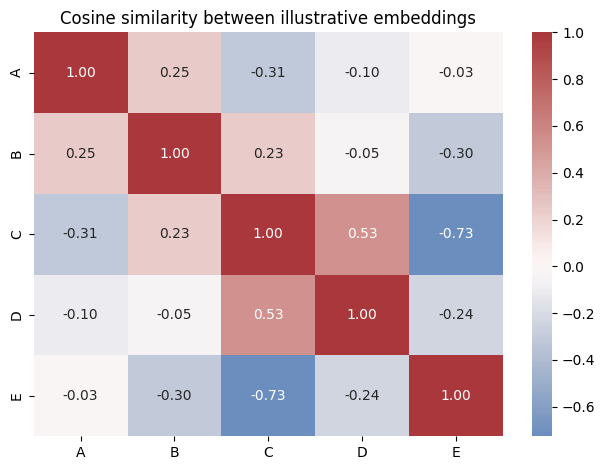

In [3]:
from sklearn.metrics.pairwise import cosine_similarity
embeddings = rng.normal(size=(5, 8))
similarity = cosine_similarity(embeddings)
sns.heatmap(similarity, annot=True, fmt=".2f", cmap="vlag", center=0, xticklabels=list("ABCDE"), yticklabels=list("ABCDE"))
plt.title("Cosine similarity between illustrative embeddings")
plt.tight_layout()

## Practice
1. Verify attention weights sum to one row-wise.
2. Explain why dividing by `sqrt(d_k)` helps stabilize dot-product magnitudes.
3. Give an example where token meaning depends on context.